# 09. NEB

- Teaches how to find a reaction barrier: a chain of structures, called a band, is laid between two relaxed endpoints and relaxed as one object, and the highest point of the relaxed chain is the estimate of the transition state
- A calculation that starts from two relaxed structures instead of one, and whose answer depends on three settings that the command fills in silently if you leave them out, canon `C6`
- One reaction on one surface: an O atom on Pt(1 1 1) hopping from the `fcc` hollow to the neighbouring `hcp` hollow, with the model `mace` in every command
- Before you start: modules 00 to 08 finished, the `mlip-mace` environment active, and Jupyter Lab running
    - The kernel shown at the top right of this notebook is "Python 3 (ipykernel)", the Python of that environment
    - The model weights sit in `~/.cache/mace/` from step 10 of module 00, so nothing is downloaded here
    - `asetools`, the package that draws the energy profile, was installed in module 00 together with `mliprun`
- After this you can run a band from the terminal between two relaxed endpoints, read the files of it that carry results, draw the profile and read the forward and the backward barrier from it, check that the band is not torn, restart it with a tighter force target, and say which of its settings are decisions of the project and not defaults

### Before you run this for a project

- The values in this notebook are teaching values, chosen so it runs on a laptop in minutes
- In a project, the items below are decided by your supervisor and written in the project's `CANON.md`; they are never taken from a tool default
    - `C1` MLIP model and head: this notebook uses `mace` (MACE-MP-0); the project may use another
    - `C4` one convergence target across an energy diagram: the endpoints and the band are converged to the same criterion; here both use `--fmax 0.05`, and the section on restarting is where a band is tightened and what that does to this rule
    - `C6` the number of intermediate images, the spring constant `k` and the climbing image on or off: decided per project; the platform defaults (5 images, `k` of 0.1, climbing image on) run silently if you leave the options out, and the last section lays them next to the project's own values
    - `C7` force convergence alone never certifies a band: a band whose images have torn apart is not converged whatever its `fmax` says, and the section on a healthy band computes one of the two checks for it
- If a value is not recorded, ask before running; the tool will not stop you

## 0. The setup cell

- Run this cell first, every time you open the notebook
- This notebook runs `mliprun` commands from the terminal side, as module 07 did, and reads the files they write
    - `work/` fills up as you go: `work/IS/` and `work/FS/` for the two endpoints and `work/neb/` for the band
- `sys.path.insert(0, str(Path("../../scripts").resolve()))` puts the repository's `scripts` folder at the front of the list of folders Python searches, as in modules 07 and 08, so `from onboarding_structures import ...` works
- `sys`, `pathlib`, `json`, `subprocess`, `time` and `importlib.metadata` all come with Python
    - `version` comes from `importlib.metadata`, and `version("mliprun")` gives the version of an installed package as text
- `numpy` is imported under the short name `np`, `pandas` under `pd` and `matplotlib.pyplot` under `plt`, as in earlier modules
- `write` and `read` come from `ase.io`, as in modules 07 and 08, and `plot_atoms` comes from `ase.visualize.plot`, as in modules 04 and 05
- `find_mic` comes from `ase.geometry`
    - Given the vectors between two sets of positions and the cell, it returns each vector shortened across the periodic boundary where that is shorter, together with its length
- `plot_nebs` comes from `asetools.pathways`, and it is the one function this group draws a NEB energy profile with
- `MLIP = Path(sys.executable).parent / "mlip"` is the `mlip` command of this environment, the same line modules 07 and 08 used
    - In the terminal you type `mlip` on its own, with the `mlip-mace` environment active, and that is what the command lines printed below show
- `run_mlip(arguments, folder=None)` prints the command as you would type it, runs it, prints how long it took, and stops the notebook if the command itself failed
    - `folder` is the folder the command runs in, and it is new in this module: the band writes its files into the folder it is run from, so the notebook runs it from `work/neb`, as you would `cd work/neb` first in a terminal
    - The cell prints that folder whenever it is given, so you can see which commands were run from where
- `shorten(text)`, `last_lines(text, n)` and `first_lines(text, n)` replace this computer's own folder names in a block of terminal output and keep its last or first `n` lines that carry anything
    - Nothing else is changed; run the same command in a terminal and you see the same lines with the full paths in them
- `final_stage(folder)` reads `mliprun_run.json` in a folder and returns its last stage, as in modules 07 and 08

In [1]:
import json
import subprocess
import sys
import time
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ase.geometry import find_mic
from ase.io import read, write
from ase.visualize.plot import plot_atoms
from asetools.pathways import plot_nebs

sys.path.insert(0, str(Path("../../scripts").resolve()))
from onboarding_structures import pt111_with_adsorbate

WORK = Path("work")
WORK.mkdir(exist_ok=True)

MLIP = Path(sys.executable).parent / "mlip"
HERE = Path.cwd()
ENVIRONMENT = Path(sys.executable).parent.parent
HOME = Path.home()


def shorten(text):
    """Replace this computer's own folder names in a block of terminal output."""
    return (text.replace(str(HERE) + "/", "")
                .replace(str(ENVIRONMENT), "<environment>")
                .replace(str(HOME), "~"))


def last_lines(text, n):
    """The last n lines of a block of output that carry anything."""
    kept = [line for line in shorten(text).splitlines() if line.strip()]
    return "\n".join(kept[-n:])


def first_lines(text, n):
    """The first n lines of a block of output that carry anything."""
    kept = [line for line in shorten(text).splitlines() if line.strip()]
    return "\n".join(kept[:n])


def run_mlip(arguments, folder=None):
    """Run one mlip command, from the given folder if there is one, and return the result."""
    print("Command, as you would type it in the terminal")
    print(" ".join(["mlip"] + arguments))
    if folder is not None:
        print("Folder the command is run from")
        print(folder)
    started = time.perf_counter()
    result = subprocess.run([str(MLIP)] + arguments, capture_output=True, text=True,
                            cwd=folder)
    print()
    print("Seconds the command took")
    print(round(time.perf_counter() - started, 1))
    if result.returncode != 0:
        print()
        print("The command failed, and this is the end of what it wrote to its error stream")
        print(last_lines(result.stderr, 15))
        raise SystemExit("mlip command failed")
    return result


def final_stage(folder):
    """The last stage of the run record mliprun wrote in that folder."""
    record = json.loads((Path(folder) / "mliprun_run.json").read_text())
    return record["stages"][-1]


print("Folder this notebook writes into")
print(WORK)
print("The mlip command of this environment was found")
print(MLIP.exists())

Folder this notebook writes into
work
The mlip command of this environment was found
True


## 1. What a barrier is

- A reaction goes from one minimum of the energy to the next, and the barrier is how high the lowest route between them rises on the way
    - The lowest route is the minimum energy path: at every point of it the energy is a minimum in every direction across the path, and it only rises or falls along it
    - Its highest point is a first-order saddle, the kind of point module 08 described as having exactly one imaginary frequency, along the direction the reaction runs
    - The forward barrier is the energy of that saddle minus the energy of the initial state, and the backward barrier is the same saddle minus the energy of the final state; a reaction has two barriers, and they differ by the reaction energy
- The nudged elastic band method finds that route without being told where the saddle is
    - It copies the structure into a chain of images, each image one full structure, from the initial state to the final state
    - The two end images are the endpoints, and the band never moves them; the images between them are the intermediate images, and they are what is relaxed
    - Each intermediate image is pushed by the part of the real force that points across the path, which pulls it onto the minimum energy path, and by a spring force along the path, which sets the spacing between neighbouring images
    - "Nudged" is that split: the real force along the path is removed and replaced by the spring, so the springs set the spacing and the real forces set the route
    - Removing the real force along the path is what stops the images from sliding down into the two minima, which the springs alone would not do
- The climbing image is how the band reaches the saddle itself and not just its neighbourhood
    - At every step the highest intermediate image is released from the springs and its force along the path is reversed, so it climbs the path while the force across it still pulls it onto the route
    - Only an intermediate image can climb, because the code takes the highest of the images between the endpoints
    - Without it the band is a picture of the path, and its highest image sits below the saddle by however far the images happen to fall from it
- The settings that decide a band are the number of intermediate images, the spring constant `k` in eV/Å², and whether the climbing image is on, which is canon `C6`
    - More images draw the path with more points, and each intermediate image costs one more force call at every step
    - In ASE's NEB, which this command uses, `k` changes how even the spacing of the images is and how fast the band converges; with the climbing image on it does not change where the climbing image ends, because that image feels no spring
    - So the number is still a decision and not a detail, since it sets the spacing of the images other than the climbing image, and the cost of the run
- `pd.DataFrame({...})` builds a table from a dictionary whose keys become the column names, as in module 01
- `table["E"].iloc[0]` is the first value of a column and `.iloc[-1]` is the last one, and `.max()` is the largest
- `plot_nebs([table], font="large")` draws one profile per table in the list, and it reads two columns by name
    - `E` is the energy of each image, and the column named `i` has to exist, but the x axis is the row position of each image and not the values in `i`
    - So the table must list the images in path order
    - It subtracts the first image's energy itself, so absolute energies go in, and it draws the figure and shows it without returning anything
- The energies below are made up, to show the shape before the real band is run
- In the plot:
    - The x axis is the image number and not a distance, so the spacing of the points says nothing about how far apart the structures are
    - The y axis is the energy of each image minus the energy of image 0; the dash-dot line is zero
    - The forward barrier is the height of the highest point above that zero line, and the backward barrier is its height above the last point

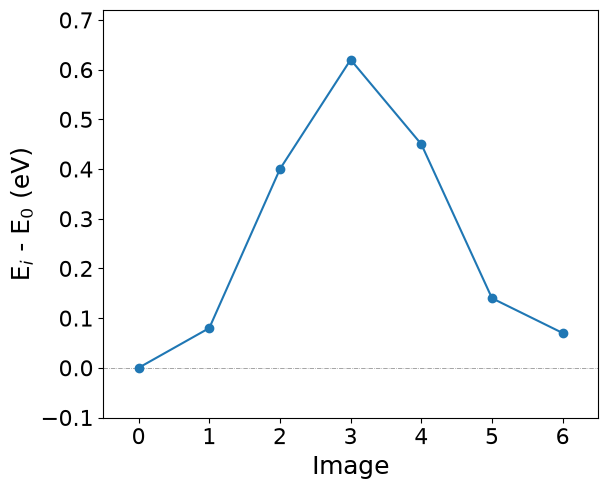

Energy of each made-up image relative to image 0 (eV)
[0.0, 0.08, 0.4, 0.62, 0.45, 0.14, 0.07]
Forward barrier of the made-up band (eV)
0.62
Backward barrier of the made-up band (eV)
0.55


In [2]:
made_up = pd.DataFrame({"i": range(7),
                        "E": [-120.00, -119.92, -119.60, -119.38, -119.55, -119.86, -119.93]})
plot_nebs([made_up], font="large")

relative_made_up = made_up["E"] - made_up["E"].iloc[0]

print("Energy of each made-up image relative to image 0 (eV)")
print([round(float(value), 2) for value in relative_made_up])
print("Forward barrier of the made-up band (eV)")
print(round(float(relative_made_up.max()), 2))
print("Backward barrier of the made-up band (eV)")
print(round(float(made_up["E"].max() - made_up["E"].iloc[-1]), 2))

## 2. Endpoints

- The band needs two relaxed structures to start from, and its answer can be no better than they are
    - The initial state is one O atom in the `fcc` hollow of the Pt(1 1 1) slab of module 05 and the final state is the same atom in the `hcp` hollow of the same slab
    - Each is relaxed with the module 07 command, `mlip optimize run --structure work/IS/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200`, into `work/IS/` and `work/FS/`
    - The relaxed geometry of each is `opt_final.vasp` in its folder, the file the band reads in the next section
- Both are relaxed to the same `--fmax 0.05` with the same optimizer, canon `C4`, and the band that follows uses `--fmax 0.05` as well
- `mliprun` names the relaxed file after its log file, and that name holds only while the command is not given `--logfile`, so these commands do not give it
- A relaxed endpoint is a result only if it converged, canon `K1`, and the cell stops the notebook if either one did not, because a band built on an unconverged endpoint is a band between two arbitrary points
- Module 07 relaxed the same two structures with the same command and found `hcp` below `fcc` with this model; that is a candidate to put to DFT at the project's level of theory, and this notebook does not settle it
    - So the reaction energy of the hop from `fcc` to `hcp` comes out negative here, and the cell prints the sign it gets
- `pd.DataFrame(rows).to_string(index=False)` prints a list of dictionaries as an aligned table without row numbers, as in earlier modules
- In the table:
    - One row per endpoint, with the steps taken, the `converged` label, the force reached and the final energy

In [3]:
IS_DIR = WORK / "IS"
FS_DIR = WORK / "FS"


def relax_endpoint(folder, site):
    """Write one O-on-Pt(111) structure into folder/POSCAR and relax it there."""
    folder.mkdir(parents=True, exist_ok=True)
    write(folder / "POSCAR", pt111_with_adsorbate("O", site),
          format="vasp", direct=True, sort=True)
    return run_mlip(["optimize", "run",
                     "--structure", str(folder / "POSCAR"),
                     "--mlip", "mace",
                     "--device", "cpu",
                     "--fmax", "0.05",
                     "--optimizer", "bfgs",
                     "--max-steps", "200"])


relax_endpoint(IS_DIR, "fcc")
print()
relax_endpoint(FS_DIR, "hcp")

rows = []
energies = {}
for label, site, folder in (("initial state", "fcc", IS_DIR), ("final state", "hcp", FS_DIR)):
    stage = final_stage(folder)
    energies[label] = stage["results"]["final_energy_eV"]
    rows.append({"endpoint": label,
                 "O site": site,
                 "steps": stage["steps"],
                 "converged": stage["results"]["converged"],
                 "fmax reached (eV/Å)": round(stage["results"]["final_fmax_eV_per_A"], 4),
                 "energy (eV)": round(stage["results"]["final_energy_eV"], 3)})

print()
print("The two endpoints")
print(pd.DataFrame(rows).to_string(index=False))

print()
print("Energy of the final state minus the initial state (eV)")
print(round(energies["final state"] - energies["initial state"], 3))

if not all(row["converged"] for row in rows):
    raise SystemExit("an endpoint did not converge: do not build a band on it")

Command, as you would type it in the terminal
mlip optimize run --structure work/IS/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200



Seconds the command took
15.6

Command, as you would type it in the terminal
mlip optimize run --structure work/FS/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200



Seconds the command took
7.4

The two endpoints
     endpoint O site  steps  converged  fmax reached (eV/Å)  energy (eV)
initial state    fcc     16       True               0.0442     -158.819
  final state    hcp     25       True               0.0437     -158.944

Energy of the final state minus the initial state (eV)
-0.125


## 3. Run the band

- The command, as you would type it from inside `work/neb` with the `mlip-mace` environment active:
    - `mlip neb run --initial ../IS/opt_final.vasp --final ../FS/opt_final.vasp --mlip mace --num-images 5 --k 0.1 --climb --fmax 0.05 --neb-max-steps 300 --no-optimize-endpoints --device cpu`
- The band writes into the folder it is run from, and reads its two structures from paths relative to that folder
    - The command takes the folder it was started in as its output folder, so the cell runs it with `folder=NEB_DIR`, the folder `work/neb`, which is what the `cwd` argument of `subprocess.run` does underneath
    - The two structures are `../IS/opt_final.vasp` and `../FS/opt_final.vasp` from there, one folder up and then into `IS` and `FS`
- Every value in it is named on purpose
    - `--mlip mace` names the model, canon `C1`; leaving `--mlip` out makes `mlip neb run` pick one for you, so this course never leaves it out
    - `--num-images 5`, `--k 0.1` and `--climb` are the three settings of canon `C6`: five intermediate images, which makes seven in all with the two endpoints, a spring constant of 0.1 eV/Å², and the climbing image on
    - `--fmax 0.05` is the force the band must get below, the same target as the endpoints
    - `--neb-max-steps 300` is a ceiling on the optimizer steps, as `--max-steps` was for a relaxation
    - `--device cpu` runs the model on the processor
- `--no-optimize-endpoints` is there because the endpoints were already relaxed in the section above
    - Left out, the command relaxes both endpoints itself first, to its own defaults of `--endpoint-fmax 0.01` with `bfgs` and at most 200 steps, which is a tighter target than the band's and breaks the one-target rule of canon `C4`
    - With it, the command skips that relaxation, writes none of the endpoint files that go with it, and skips the check that the two endpoints differ
    - The two end images of the band are the two relaxed structures, and the table of the next section shows that image 0 and the last image carry the energies the two relaxations ended on
- What the command does before the band runs
    - It places the intermediate images on a straight line between the two endpoints, then relaxes that guess with IDPP, the image dependent pair potential, which is a cheap model of the distances between pairs of atoms; it prints `Interpolating with IDPP...` when it starts
    - The IDPP relaxation stops at a force of 0.1 eV/Å or after 100 steps, and `neb_parameters.txt` shows both numbers; the cell prints the last row of `idpp.log`, which shows how many steps it actually took
    - It builds a separate model calculator for each of the seven images, so the loading lines of the model appear once per image in the output
- What the command leaves in `work/neb`, besides the log of every step
    - `neb_parameters.txt`, the settings the band ran with, the file a restart reads
    - `A2B.traj`, the seven final images, and `A2B_full.traj`, the seven images at every step, step 0 included
    - `neb_data.csv`, the energy of each of the seven images, and `neb_convergence.csv`, the largest force and the barrier at every step
    - `00/` to `06/`, one folder per image, each with a `POSCAR`
    - `idpp.traj` and `idpp.log` from the interpolation, and `mliprun_run.json`, the run record
- The optimizer that moves the band is `FIRE`, because `--neb-optimizer` was not given; neither it nor the IDPP numbers are in this module's canon list, so they are two more things the command decides for you if you do not ask, and `neb_parameters.txt` shows both
- The outcome of a band is read from the run record and not from the return code, canon `K1`
    - The last stage's `status` is `converged` or `not_converged`, and its `steps` is the number of optimizer steps taken
    - Its `parameters` hold the settings that stage ran with, each one as a `value` and the `source` it came from, and the cell reads the step ceiling out of them
    - Unlike a relaxation, the `results` of this stage have no `converged` key: the label is the stage's `status`
- In the printed output:
    - The first three and the last eighteen lines the command printed, with this computer's folder names removed
    - The number of times the output says the model was loaded
    - The files the command left, and the last row of `idpp.log`
    - The frames in `A2B_full.traj` against the steps the band took
    - The outcome of the band from the run record, and the file that records what was run

In [4]:
NEB_DIR = WORK / "neb"
NEB_DIR.mkdir(exist_ok=True)

result = run_mlip(["neb", "run",
                   "--initial", "../IS/opt_final.vasp",
                   "--final", "../FS/opt_final.vasp",
                   "--mlip", "mace",
                   "--num-images", "5",
                   "--k", "0.1",
                   "--climb",
                   "--fmax", "0.05",
                   "--neb-max-steps", "300",
                   "--no-optimize-endpoints",
                   "--device", "cpu"],
                  folder=NEB_DIR)

print()
print("First lines the command printed")
print(first_lines(result.stdout, 3))
print()
print("Last lines the command printed")
print(last_lines(result.stdout, 18))

print()
print("Times the output says the MACE-MP-0 weights were loaded")
print(sum("Using Materials Project MACE" in line for line in result.stdout.splitlines()))

print()
print("Files and folders in work/neb after the run")
print(sorted(path.name for path in NEB_DIR.iterdir() if not path.name.startswith("bkup_")))

idpp_row = (NEB_DIR / "idpp.log").read_text().splitlines()[-1].split()

print()
print("Last step of the IDPP relaxation, from idpp.log")
print(idpp_row[1])
print("Force at that step, against the IDPP target of 0.1 eV/Å")
print(round(float(idpp_row[-1]), 4))

stage = final_stage(NEB_DIR)
frames = read(NEB_DIR / "A2B_full.traj", index=":")

print()
print("Status of the last stage of mliprun_run.json")
print(stage["status"])
print("Optimizer steps taken")
print(stage["steps"])
print("Frames in A2B_full.traj")
print(len(frames))
print("Step ceiling given")
print(stage["parameters"]["max_steps"]["value"])
print("Largest force of the band at the last step (eV/Å)")
print(round(stage["results"]["final_fmax_eV_per_A"], 4))
print("A key called converged in the results of that stage")
print("converged" in stage["results"])

print()
print("neb_parameters.txt, the settings this band ran with")
print(shorten((NEB_DIR / "neb_parameters.txt").read_text()))

Command, as you would type it in the terminal
mlip neb run --initial ../IS/opt_final.vasp --final ../FS/opt_final.vasp --mlip mace --num-images 5 --k 0.1 --climb --fmax 0.05 --neb-max-steps 300 --no-optimize-endpoints --device cpu
Folder the command is run from
work/neb



Seconds the command took
21.8

First lines the command printed
Using MLIP: mace
 Interpolating with IDPP...
Running NEB optimization (optimizer=FIRE, climb=True, max_steps=300)...

Last lines the command printed
Processing results...
Exporting POSCARs...
NEB complete. Output written to:
 - work/neb/neb.log
 - work/neb/neb_convergence.csv
 - work/neb/A2B.traj
 - work/neb/A2B_full.traj
 - work/neb/idpp.traj
 - work/neb/idpp.log
 - work/neb/neb_data.csv
 - work/neb/neb_parameters.txt
 - work/neb/00/POSCAR
 - work/neb/01/POSCAR
 - work/neb/02/POSCAR
 - work/neb/03/POSCAR
 - work/neb/04/POSCAR
 - work/neb/05/POSCAR
 - work/neb/06/POSCAR

Times the output says the MACE-MP-0 weights were loaded
7

Files and folders in work/neb after the run
['00', '01', '02', '03', '04', '05', '06', 'A2B.traj', 'A2B_full.traj', 'idpp.log', 'idpp.traj', 'mliprun_run.json', 'neb.log', 'neb_convergence.csv', 'neb_data.csv', 'neb_parameters.txt']

Last step of the IDPP relaxation, from idpp.log
0
Force at that s

## 4. Read the band

- `neb_data.csv` has one row per image, with the columns `image_index`, `energy` and `relative_energy`
    - `pd.read_csv(path)` reads a table from a csv file, as in module 07
    - `list(table.columns)` gives the column names
    - `energy.idxmax()` is the row label of the largest value of a column, and here the row label is the image number
- The cell works the energies out itself from the `energy` column, and the run record's own numbers are printed beside them as a cross-check
    - Relative to the initial state means each energy minus the energy of image 0
    - The reaction energy is the energy of the last image minus the energy of the first
    - The forward barrier is the largest energy minus the first, and the backward barrier is the largest energy minus the last
    - These are energies of the seven images, and the highest of them is an estimate of the saddle that is better because the climbing image was on
    - `ts_at_endpoint` in the record says whether the highest image is an endpoint, and when it is, no saddle was found between them and the number is not a barrier
- In the table:
    - One row per image, with its energy and its energy relative to image 0
    - The highest image is image 3, about 0.34 eV above image 0, and the last image is 0.125 eV below it
    - The forward barrier is about 0.34 eV (this run printed 0.335), the backward barrier is 0.46 eV, and the run record gives the same two numbers
    - The forward barrier sits close to a rounding boundary: a run on your computer may print 0.335 or 0.336
    - The reaction energy is negative, which is the order module 07 found for these two sites with this model: `hcp` below `fcc`
- In the profile, drawn with the same `plot_nebs` call as the made-up one from a table with the two columns it reads, `i` and `E`:
    - The path rises from image 0 to image 3, falls from image 3 through the zero line, and ends at image 6 below where it began
    - Image 1 sits only 0.050 eV above image 0, while image 2 sits 0.271 eV above it, so the rise is far from even between neighbouring images
- These numbers are barriers of this model on this band
    - They come from one model, `mace`, and no DFT barrier was computed for this hop, so the 0.34 eV is a candidate to put to DFT in the way module 07 put the site order, and nothing more
    - The band converged with the climbing image on, so the highest image is this model's saddle point on the path this band found, to within the force target of 0.05 eV/Å
    - What remains uncertain is that tolerance, the one path that was tried, and the one model; the number of images does not decide where the climbing image ends for this path
- Module 08 stopped short of a barrier: its bridge geometry was placed by hand and was not a stationary point, and it left a path between the two hollows to this module
    - This band is that path, and the next section reads where the O atom is along it

Columns of neb_data.csv
['image_index', 'energy', 'relative_energy']

The seven images
 image  energy (eV)  relative to image 0 (eV)
     0     -158.819                     0.000
     1     -158.769                     0.050
     2     -158.548                     0.271
     3     -158.484                     0.335
     4     -158.611                     0.208
     5     -158.882                    -0.062
     6     -158.944                    -0.125

Reaction energy, last image minus first (eV)
-0.125
Forward barrier (eV)
0.335
Backward barrier (eV)
0.46
Highest image
3

Forward barrier in the run record (eV)
0.335
Backward barrier in the run record (eV)
0.46
Highest image in the run record
3
Highest image is an endpoint, in the run record
False


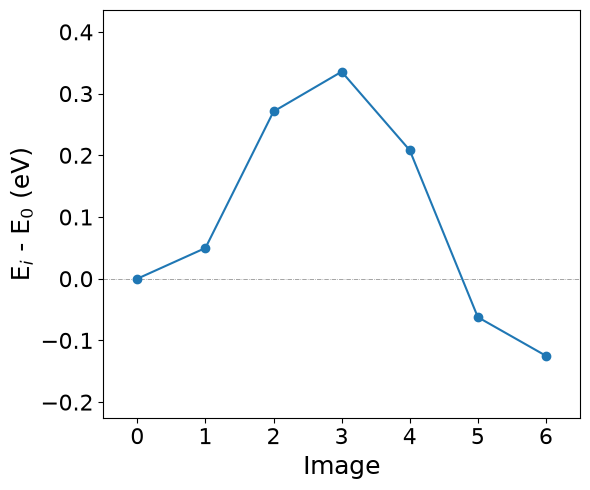

In [5]:
band = pd.read_csv(NEB_DIR / "neb_data.csv")
energy = band["energy"]
relative = energy - energy.iloc[0]

reaction_energy = float(energy.iloc[-1] - energy.iloc[0])
forward_barrier = float(relative.max())
backward_barrier = float(energy.max() - energy.iloc[-1])
highest_image = int(energy.idxmax())

print("Columns of neb_data.csv")
print(list(band.columns))

rows = [{"image": int(i), "energy (eV)": round(float(e), 3), "relative to image 0 (eV)": round(float(r), 3)}
        for i, e, r in zip(band["image_index"], energy, relative)]
print()
print("The seven images")
print(pd.DataFrame(rows).to_string(index=False))

print()
print("Reaction energy, last image minus first (eV)")
print(round(reaction_energy, 3))
print("Forward barrier (eV)")
print(round(forward_barrier, 3))
print("Backward barrier (eV)")
print(round(backward_barrier, 3))
print("Highest image")
print(highest_image)

print()
print("Forward barrier in the run record (eV)")
print(round(stage["results"]["forward_barrier_eV"], 3))
print("Backward barrier in the run record (eV)")
print(round(stage["results"]["reverse_barrier_eV"], 3))
print("Highest image in the run record")
print(stage["results"]["ts_image_index"])
print("Highest image is an endpoint, in the run record")
print(stage["results"]["ts_at_endpoint"])

profile = pd.DataFrame({"i": band["image_index"], "E": energy})
plot_nebs([profile], font="large")

### 4a. Where the O atom is along the band

- The profile gives energies and says nothing about what moved, so the images are read back from `A2B.traj`
    - `read(path, index=":")` loads every frame of a trajectory file as a list of structures, here the seven images in order
    - The constraint of the relaxed endpoints comes back with each image, so the cell also counts the atoms each image holds fixed
- `o_environment(atoms)` measures the O atom of one image, the way module 07's `o_geometry` did
    - `atoms.get_distances(i_o, pt_indices, mic=True)` gives the distances in Å from the O to every Pt atom, and `np.sort(...)` puts them in increasing order
    - The three smallest are the O's three nearest Pt atoms: in a three-fold hollow they are about equal, and at a bridge two of them are about equal and the third is longer; that test alone does not name a bridge, because images 1 to 5 all show two equal distances: the O keeps to a line that is equally far from two Pt atoms
- The pictures are top views of the slab around the hop, one panel per image
    - `plot_atoms(atoms, ax, radii=0.5, show_unit_cell=0)` draws one structure into one panel, with the cell outline left out, and it draws no axes
    - The x and y limits cut each picture down to a window 5.2 Å across, centred halfway between the O atom of the first image and the O atom of the last, so the Pt atoms at the edge of a panel are cut off
- In the table:
    - One row per image, with its energy relative to image 0, the z coordinate of the O atom, and its three nearest Pt distances
    - The first and last image have three equal distances, 2.113 Å and 2.089 Å, which is an atom in a three-fold hollow
    - The highest image has two Pt atoms at 2.039 Å and a third at 2.962 Å, and its O atom is about 0.32 Å higher than in image 0
    - Those are the numbers of this one image and nothing more is claimed from them: the image is the saddle point of this band to within its force target, and the table does not say that it is a bridge site
- In the pictures:
    - The red atom is O, and it moves across the surface from the first panel to the last
    - It has three Pt neighbours in the first and the last panel, and in the middle panels it sits between two of them

Images read from A2B.traj
7
Atoms held fixed in each image
[9, 9, 9, 9, 9, 9, 9]

The O atom along the band
 image  relative energy (eV)  O z (Å)  nearest Pt (Å)  second Pt (Å)  third Pt (Å)
     0                 0.000   16.180           2.113          2.113         2.113
     1                 0.050   16.266           2.073          2.073         2.235
     2                 0.271   16.416           2.039          2.039         2.626
     3                 0.335   16.501           2.039          2.039         2.962
     4                 0.208   16.397           2.040          2.040         2.570
     5                -0.062   16.270           2.082          2.082         2.191
     6                -0.125   16.270           2.089          2.089         2.089


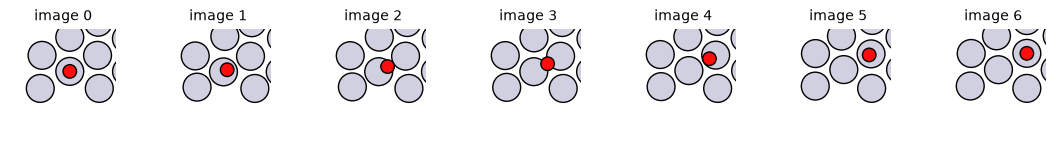

In [6]:
images = read(NEB_DIR / "A2B.traj", index=":")


def o_environment(atoms):
    """z coordinate of the O atom and its three nearest Pt distances in one structure."""
    symbols = atoms.get_chemical_symbols()
    i_o = symbols.index("O")
    pt_indices = [i for i, symbol in enumerate(symbols) if symbol == "Pt"]
    distances = np.sort(atoms.get_distances(i_o, pt_indices, mic=True))
    return float(atoms.positions[i_o, 2]), distances[:3]


rows = []
for k, atoms in enumerate(images):
    height, nearest = o_environment(atoms)
    rows.append({"image": k,
                 "relative energy (eV)": round(float(relative.iloc[k]), 3),
                 "O z (Å)": round(height, 3),
                 "nearest Pt (Å)": round(float(nearest[0]), 3),
                 "second Pt (Å)": round(float(nearest[1]), 3),
                 "third Pt (Å)": round(float(nearest[2]), 3)})

print("Images read from A2B.traj")
print(len(images))
print("Atoms held fixed in each image")
print([len(atoms.constraints[0].index) for atoms in images])

print()
print("The O atom along the band")
print(pd.DataFrame(rows).to_string(index=False))

first_o = images[0].positions[images[0].get_chemical_symbols().index("O")]
last_o = images[-1].positions[images[-1].get_chemical_symbols().index("O")]
centre = (first_o + last_o) / 2

fig, axes = plt.subplots(1, 7, figsize=(11, 1.5))
for k, (ax, atoms) in enumerate(zip(axes, images)):
    plot_atoms(atoms, ax, radii=0.5, show_unit_cell=0)
    ax.set_xlim(centre[0] - 2.6, centre[0] + 2.6)
    ax.set_ylim(centre[1] - 2.6, centre[1] + 2.6)
    ax.set_title("image " + str(k), fontsize=10)
fig.tight_layout()
plt.show()

## 5. Is the band healthy

- Force convergence alone never certifies a band, canon `C7`, because a band can reach a small force and still be a bad band
    - The `converged` label in the run record comes from one test, whether the largest force fell below `--fmax` within the step ceiling, and that test does not look at where the images are
- Canon `C7` has two checks, and they are different checks
    - The hard check is drift: each atom of each intermediate image has an allowance, made of a floor plus a factor times that atom's own travel from the initial state to the final state, and an atom that is further than that from where the starting path put it means the band exploded, so its `converged` label is false whatever `fmax` says
    - The warning check is the jump: the largest distance any atom moves between two neighbouring images, and a value above 1.0 Å flags a coarse or torn band, but it is a warning and not a failure
    - This section computes the jump only; the drift needs a floor and a factor, and a project records both, so this notebook does not invent them: your project's value, ask
- `find_mic(vectors, cell, pbc=True)` returns each displacement vector shortened across the periodic boundary where that is shorter, with its length, so an atom that crosses the cell boundary is not counted as a jump of a whole cell
- `lengths.argmax()` is the position of the largest value of an array, used to name the atom that moved furthest
- The cell also prints the reaction travel, the largest distance any atom moves between the two endpoints, and what an even spacing of that travel over the six gaps between seven images would be
    - The jumps need not be even: the springs equalise the spacing only roughly, and the climbing image feels no spring
    - So the even spacing is a yardstick for the size of the jumps, and the 1.0 Å line is the threshold
- In the table:
    - One row per pair of neighbouring images, with the largest atom displacement between them and the symbol of that atom
    - The largest jump is 0.397 Å, between images 3 and 4, and it is the O atom; no pair is above 1.0 Å, so this band raises no warning
    - The reaction travel is 1.603 Å, so an even spacing would be 0.267 Å, and the jumps run from 0.217 Å to 0.397 Å around it
    - In the last pair the atom that moves furthest is a Pt atom, so the O atom moves less than 0.217 Å there
- That one warning check is passing, and it says nothing about drift, so on its own it does not certify this band

In [7]:
rows = []
for k in range(len(images) - 1):
    vectors = images[k + 1].positions - images[k].positions
    _, lengths = find_mic(vectors, images[k].cell, pbc=True)
    atom = int(lengths.argmax())
    rows.append({"from image": k,
                 "to image": k + 1,
                 "largest displacement (Å)": round(float(lengths[atom]), 3),
                 "atom": images[k].get_chemical_symbols()[atom]})

_, travel_lengths = find_mic(images[-1].positions - images[0].positions,
                             images[0].cell, pbc=True)
travel = float(travel_lengths.max())
largest_jump = max(row["largest displacement (Å)"] for row in rows)

print("Displacement of the atoms between neighbouring images")
print(pd.DataFrame(rows).to_string(index=False))

print()
print("Largest jump between neighbouring images (Å)")
print(largest_jump)
print("Pairs of neighbouring images with a jump above 1.0 Å")
print(sum(row["largest displacement (Å)"] > 1.0 for row in rows))

print()
print("Reaction travel, largest displacement of any atom between the endpoints (Å)")
print(round(travel, 3))
print("That travel spread evenly over the six gaps (Å)")
print(round(travel / 6, 3))

Displacement of the atoms between neighbouring images
 from image  to image  largest displacement (Å) atom
          0         1                     0.225    O
          1         2                     0.329    O
          2         3                     0.289    O
          3         4                     0.397    O
          4         5                     0.301    O
          5         6                     0.217   Pt

Largest jump between neighbouring images (Å)
0.397
Pairs of neighbouring images with a jump above 1.0 Å
0

Reaction travel, largest displacement of any atom between the endpoints (Å)
1.603
That travel spread evenly over the six gaps (Å)
0.267


## 6. Restart and change settings

- The command, as you would type it from inside `work/neb`:
    - `mlip neb run --restart --mlip mace --fmax 0.03`
- A restart continues a band from where it stopped, with some settings changed, and it needs two files in the folder
    - `A2B_full.traj`, from which it takes the last seven frames, which are the images as they stood at the last step of the run before
    - `neb_parameters.txt`, from which it takes the model, the number of images and every setting you do not give again
    - Nothing is interpolated again and the endpoints are not relaxed again
- Before it runs, a restart moves the files of the previous run into a new folder inside the band's folder, named `bkup_` followed by the date and time
    - It moves the output files it finds, the folders `00/` to `06/`, and copies `neb_parameters.txt`, so the folder holds a complete record of the run it replaced
    - The repository's `.gitignore` ignores folders that start with `bkup_`, because these are restart backups and not results
    - The restart writes the files it needs again, but not the interpolation files: `idpp.traj` and `idpp.log` stay in the backup, and the new `A2B_full.traj` holds only the restarted steps
- What may change on a restart, because the command reads it when you give it and takes the saved value when you do not
    - `--fmax`, `--k`, `--climb` or `--no-climb`, `--neb-optimizer`, `--neb-max-steps`, `--dyneb`, `--scale-fmax`, `--log` and `--device`
    - The model too: the command accepts a different `--mlip` and only logs a warning, but a band whose first part came from one model and whose second part came from another has no single energy zero, canon `C1`, so do not
    - Naming the same model again, as the command above does, changes nothing: the command prints `MLIP override detected: mace`, as the first lines below show, and keeps the model it saved
- What may not change
    - `--initial`, `--final`, `--num-images`, `--relax-atoms` and `--optimize-endpoints`: the command prints an error saying they are loaded from `neb_parameters.txt` and stops, before it touches anything
    - The number of images is the one that matters most here: it is canon `C6`, and a different number of images is a different band, started in a new folder from the two endpoints
    - `--interp-fmax`, `--interp-steps` and the three `--endpoint-` options are accepted and then not used, because a restart skips the steps they belong to
- This restart tightens the band to `--fmax 0.03` and leaves the endpoints at 0.05, which breaks canon `C4`
    - A barrier at 0.03 is not a better number than the one at 0.05 for that reason: its endpoints and its band are at two different targets, and a report has to say so, or relax the endpoints to 0.03 as well
    - It is here to show what a restart does, not as the way to finish a band
- The run record gains a second stage and keeps the first
    - The restart's stage has the kind `neb-restart`, and its own `fmax`, so the table below reads the target of each stage from the stage
- `NEB_DIR.glob("bkup_*")` lists the folders of `work/neb` whose names start with `bkup_`, and the cell takes the last one in the sorted list, which is the newest because the date and time in the name sort in order
- In the printed output:
    - The first thirteen lines the command printed, which show what it loaded, what you overrode and what it backed up
    - The folder after the restart and the backup folder, and the frames in the new `A2B_full.traj` against the old one
    - The stages of the run record, and the two barriers side by side
- What the restart did to this band
    - It took 6 more steps and ended at a largest force of 0.0293 eV/Å, below its new target of 0.03
    - Each barrier moved by less than 0.001 eV, and the reaction energy did not change, because the two endpoints are not moved
    - The cell prints these changes to four decimals, because each is too small to show at three
    - That is one band and one change of target, and it says nothing about how much a tighter target moves a barrier on another band

In [8]:
barrier_before = forward_barrier
reverse_before = backward_barrier
reaction_before = reaction_energy

restart = run_mlip(["neb", "run", "--restart", "--mlip", "mace", "--fmax", "0.03"],
                   folder=NEB_DIR)

print()
print("First lines the command printed")
print(first_lines(restart.stdout, 13))

print()
print("Files and folders in work/neb after the restart")
print(sorted(path.name for path in NEB_DIR.iterdir()))
backup_dir = sorted(NEB_DIR.glob("bkup_*"))[-1]
print("Files and folders in the backup folder")
print(sorted(path.name for path in backup_dir.iterdir()))
print("Frames in A2B_full.traj of the backup")
print(len(read(backup_dir / "A2B_full.traj", index=":")))
print("Frames in the new A2B_full.traj")
print(len(read(NEB_DIR / "A2B_full.traj", index=":")))

record = json.loads((NEB_DIR / "mliprun_run.json").read_text())
rows = [{"stage": s["index"],
         "kind": s["kind"],
         "status": s["status"],
         "steps": s["steps"],
         "fmax asked for (eV/Å)": s["parameters"]["fmax"]["value"],
         "largest force reached (eV/Å)": round(s["results"]["final_fmax_eV_per_A"], 4),
         "forward barrier (eV)": round(s["results"]["forward_barrier_eV"], 4)}
        for s in record["stages"]]

print()
print("The stages of the run record")
print(pd.DataFrame(rows).to_string(index=False))

band_after = pd.read_csv(NEB_DIR / "neb_data.csv")
energy_after = band_after["energy"]

print()
print("Forward barrier before the restart (eV)")
print(round(barrier_before, 4))
print("Forward barrier after the restart (eV)")
print(round(float(energy_after.max() - energy_after.iloc[0]), 4))
print("Backward barrier before the restart (eV)")
print(round(reverse_before, 4))
print("Backward barrier after the restart (eV)")
print(round(float(energy_after.max() - energy_after.iloc[-1]), 4))
print("Change in the forward barrier (eV)")
print(round(float(energy_after.max() - energy_after.iloc[0]) - barrier_before, 4))
print("Change in the backward barrier (eV)")
print(round(float(energy_after.max() - energy_after.iloc[-1]) - reverse_before, 4))
print("Change in the reaction energy (eV)")
print(round(float(energy_after.iloc[-1] - energy_after.iloc[0]) - reaction_before, 4))

Command, as you would type it in the terminal
mlip neb run --restart --mlip mace --fmax 0.03
Folder the command is run from
work/neb



Seconds the command took
8.2

First lines the command printed
RESTART MODE
Loading restart files from: work/neb
   MLIP override detected: mace
Parameters loaded from neb_parameters.txt:
   - MLIP model:          mace
   - Intermediate images: 5
   - Total images:        7
Parameter overrides: MLIP: mace, fmax: 0.03
Creating backup of previous results...
   Backup created: bkup_2026.10.13_11.32.02
   Moved 15 files/folders
Skipping interpolation (loaded from restart)
Running NEB optimization (optimizer=FIRE, climb=True, max_steps=300)...

Files and folders in work/neb after the restart
['00', '01', '02', '03', '04', '05', '06', 'A2B.traj', 'A2B_full.traj', 'bkup_2026.10.13_11.32.02', 'mliprun_run.json', 'neb.log', 'neb_convergence.csv', 'neb_data.csv', 'neb_parameters.txt']
Files and folders in the backup folder
['00', '01', '02', '03', '04', '05', '06', 'A2B.traj', 'A2B_full.traj', 'idpp.log', 'idpp.traj', 'neb.log', 'neb_convergence.csv', 'neb_data.csv', 'neb_parameters.txt']
Frames

## 7. What C6 asks you to decide

- Canon `C6` is three decisions that a band makes for you when you leave them out
    - The number of intermediate images
    - The spring constant `k`
    - The climbing image, on or off
- The platform defaults below were read from the code of `neb run` in the version the cell prints, and not from the help text, which shows no value for any of the three
    - A different version of `mliprun` may default differently, so the cell prints the version above the table
- The table has two rows
    - The platform default is what the band uses if you leave the option out
    - Your project's value is what your supervisor recorded in the project's `CANON.md`; if it records nothing for `C6`, that is the case the section at the top of this notebook describes: your project's value, ask, before running
- This notebook's own three values are the same as the platform defaults, which says nothing about whether they suit a project
    - The cell reads them back from `neb_parameters.txt`, the file of what was run, rather than from the command above
- More things the command decides for you, outside `C6`
    - The optimizer, `FIRE`, and the step ceiling, 600 if you do not give `--neb-max-steps`
    - Whether the endpoints are relaxed first, which it does unless told not to, to a force target of 0.01 eV/Å
    - The IDPP settings of the starting path
- In the table:
    - The two rows, one column for each of the three decisions

In [9]:
used = {}
for line in (NEB_DIR / "neb_parameters.txt").read_text().splitlines():
    if ":" in line:
        key, value = line.split(":", 1)
        used[key.strip()] = value.strip()

print("mliprun version")
print(version("mliprun"))
print("Intermediate images in the last run")
print(used["Intermediate images"])
print("Spring constant k in the last run")
print(used["Spring constant (k)"])
print("Climbing image in the last run")
print(used["Climb"])

rows = [{"row": "platform default", "intermediate images": 5, "spring constant k (eV/Å²)": 0.1,
         "climbing image": "on"},
        {"row": "your project's value", "intermediate images": "ask", "spring constant k (eV/Å²)": "ask",
         "climbing image": "ask"}]
print()
print("The three decisions of canon C6")
print(pd.DataFrame(rows).to_string(index=False))

mliprun version
0.4.0
Intermediate images in the last run
5
Spring constant k in the last run
0.1
Climbing image in the last run
True

The three decisions of canon C6
                 row intermediate images spring constant k (eV/Å²) climbing image
    platform default                   5                       0.1             on
your project's value                 ask                       ask            ask


## Check yourself

1. A colleague sends you a barrier from a NEB run and the folder it came from.
   Which files do you open first, and what do you look for in them before you use the number?
2. A band reports `converged` with a largest force of 0.04 eV/Å, and the profile looks smooth.
   Your jump check shows 1.4 Å between two neighbouring images. Is the barrier usable, and which check would you still need?
3. You want a band with nine intermediate images, and you try `mlip neb run --restart --mlip mace --num-images 9` in the folder of a finished five-image band.
   What happens, and what do you do instead?

<details>
<summary>Answers</summary>

- `mliprun_run.json` and `neb_parameters.txt`. In the run record: the `status` of the last stage, which is where a band's `converged` label lives and not in its `results`; the stage list, to see whether the band was restarted and at which `fmax` each stage ran; and the highest image with its `ts_at_endpoint` flag, because an endpoint as the highest image means no saddle was found. In the parameters file: the model, canon `C1`; the number of images, the spring constant and the climbing image, canon `C6`; whether the endpoints were relaxed first and to what target, canon `C4`. Then read `neb_data.csv` and check the jump between neighbouring images, canon `C7`
- Not usable yet. Force convergence alone never certifies a band, canon `C7`, and the drift check has not been made. The jump above 1.0 Å is a warning and not a failure: it is the reason to look at the band, which may be coarse or torn. The check you still need is the drift check: whether any atom of any intermediate image has moved further from where the starting path put it than its allowance of a floor plus a factor times its own travel, which the project's `CANON.md` has to record because this notebook does not set it
- The command prints an error that `--num-images` cannot be given with `--restart`, because the number of images is loaded from `neb_parameters.txt`, and it stops before it changes anything. Nine images is a different band, and the number of images is canon `C6`, so it is started in a new folder from the same two endpoints with `--mlip mace --num-images 9`, and its barrier is compared with the five-image one before either is reported

</details>